# The attractor network behind the exponential map

Reproduces Fig. 4 (Sec. 3.1, Appendix J.1): the exponential map is not only an algebraic
construction, it is the **on-manifold dynamics of a gain-modulated CANN**.

The network state evolves as

$$\tau\dot z = U(v)\,z - M\sigma(z),\qquad \sigma(z) = (\|z\|^2 - 1)z \tag{7}$$

with $U$ skew-symmetric and $M$ positive definite. The Lyapunov energy
$E = \tfrac12(\|z\|^2-1)^2$ (Eq. 8) is non-increasing, because skew-symmetry kills the
transport term ($z^\top U z \equiv 0$) and positive definiteness signs the rest:

$$\tau\dot E = -2(\|z\|^2-1)^2 z^\top M z \le 0$$

So the flow reaches the unit hypersphere without any topology being imposed. Once there,
$\sigma(z^*) = 0$, the attractor term drops out, and what remains is pure transport whose
solution is exactly the exponential map, $z^*(t) = e^{tU/\tau}z^*(0)$.

The three panels show that: energy decaying to zero, the state tracking
$e^{U(t-t^*)}z^*$ once on the manifold, and — for contrast — diverging from the *static*
$z^*$, which is what transport along the manifold looks like.

The dynamics live in `expmap.attractor` and are covered by `tests/test_attractor.py`;
this notebook is the figure.

**One numerical caveat.** Forward Euler leaves the state slightly *outside* the sphere
rather than on it: a step on the transport term inflates the norm exactly, since
$\|z + \delta t\,Uz\|^2 = \|z\|^2 + \delta t^2\|Uz\|^2$ (the cross term vanishes because
$z^\top U z = 0$), and this balances the inward pull at $\|z\|-1 = O(\delta t)$. At these
settings the offset is $\approx 10^{-5}$. It is why the energy curve bottoms out and
creeps back up rather than decaying forever, and it shrinks by refining $\delta t$, not by
integrating longer. The last cell checks it.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm

from expmap.attractor import (
    exponential_map_trajectory,
    hypersphere_step,
    lyapunov_energy,
    positive_definite_matrix,
    simulate,
    skew_symmetric_matrix,
)

# Figure parameters, as used for Fig. 4. ENERGY_THRESHOLD picks the first point counted as
# being on the manifold; it is 5e-5 rather than the 1e-4 of the original notebook because
# lyapunov_energy carries the factor of 1/2 from Eq. 8, so the two select the same point.
N = 128
DT = 5e-5
T = 0.03
TAU = 1.0
NUM_TRAJECTORIES = 100
ENERGY_THRESHOLD = 5e-5
SEED = 0

STEPS = int(T / DT)
times = np.arange(STEPS) * DT

REPO_ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
FIGURE_DIR = REPO_ROOT / "figures"
FIGURE_DIR.mkdir(exist_ok=True)

print(f"Simulation steps: {STEPS}")

Simulation steps: 600


In [2]:
U = skew_symmetric_matrix(N, seed=SEED)
M = positive_definite_matrix(N, seed=SEED + 1)

# The two structural conditions the Lyapunov argument rests on. Skew-symmetry makes
# z^T U z vanish, so transport cannot change the energy; positive definiteness makes the
# remaining term strictly negative off the manifold.
assert np.allclose(U, -U.T), "U must be skew-symmetric"
assert np.linalg.eigvalsh(M).min() > 0, "M must be positive definite"

print(f"largest |Im eig(U)| = {np.abs(np.linalg.eigvals(U).imag).max():.1f}")
print(f"eig(M) in [{np.linalg.eigvalsh(M).min():.2e}, {np.linalg.eigvalsh(M).max():.2e}]")

largest |Im eig(U)| = 31.1
eig(M) in [2.29e-04, 4.94e+02]


In [3]:
rng = np.random.default_rng(SEED)

energies, exp_deviations, zstar_deviations, t_stars, post_star = [], [], [], [], []

for _ in tqdm(range(NUM_TRAJECTORIES)):
    z0 = rng.uniform(-1, 1, N) * 0.1
    z = simulate(z0, U, M, DT, T, tau=TAU)

    energy = lyapunov_energy(z)
    energies.append(energy)

    on_manifold = np.flatnonzero(energy < ENERGY_THRESHOLD)
    if not on_manifold.size:
        print("No convergence to attractor")
        continue
    star = int(on_manifold[0])  # first point counted as on the manifold

    # Closed-form prediction: pure transport of z* along the manifold. One matrix
    # exponential is enough, since expm(U dt) is orthogonal for skew U.
    predicted = exponential_map_trajectory(U, z[star], STEPS, DT, star, tau=TAU)

    deviation = np.sum((z - predicted) ** 2, axis=1)
    exp_deviations.append(deviation)
    post_star.append(deviation[star:].max())
    zstar_deviations.append(np.sum((z - z[star]) ** 2, axis=1))
    t_stars.append(times[star])

energies = np.array(energies)
exp_deviations = np.array(exp_deviations)
zstar_deviations = np.array(zstar_deviations)
t_stars = np.array(t_stars)
post_star_deviation = np.array(post_star)

print(f"{len(exp_deviations)}/{NUM_TRAJECTORIES} trajectories reached the manifold")
print(f"mean t* = {t_stars.mean():.5f}")
print(f"max deviation from the closed form, t >= t*: {post_star_deviation.max():.2e}")

  0%|          | 0/100 [00:00<?, ?it/s]

 18%|█▊        | 18/100 [00:00<00:00, 171.11it/s]

 36%|███▌      | 36/100 [00:00<00:00, 172.62it/s]

 54%|█████▍    | 54/100 [00:00<00:00, 173.18it/s]

 72%|███████▏  | 72/100 [00:00<00:00, 173.79it/s]

 90%|█████████ | 90/100 [00:00<00:00, 174.04it/s]

100%|██████████| 100/100 [00:00<00:00, 173.64it/s]

100/100 trajectories reached the manifold
mean t* = 0.01250
max deviation from the closed form, t >= t*: 3.91e-05


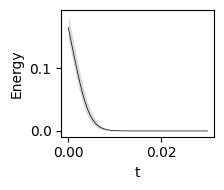

In [4]:
# Fig. 4a. The caption describes a +/-1 standard deviation envelope, so that is what is
# drawn; the original notebook plotted the individual traces instead.
mean_energy = energies.mean(axis=0)
std_energy = energies.std(axis=0)

plt.figure(figsize=(2.5, 2))
plt.fill_between(times, mean_energy - std_energy, mean_energy + std_energy, color="gray", alpha=0.3, linewidth=0)
plt.plot(times, mean_energy, "k", linewidth=0.5)
plt.xlabel("t")
plt.ylabel("Energy")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "energy_decay.svg", dpi=300, bbox_inches="tight")
plt.savefig(FIGURE_DIR / "energy_decay.png", dpi=300, bbox_inches="tight")

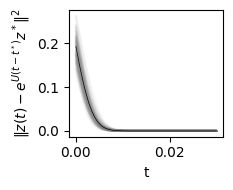

In [5]:
# Fig. 4b. Once on the manifold the state follows the exponential map of z*, so this stays
# flat at zero after t*. Before t* the state is still off-manifold, where the attractor
# term is active and the closed form does not apply.
plt.figure(figsize=(2.5, 2))
for deviation in exp_deviations:
    plt.plot(times, deviation, color="gray", alpha=0.05)
plt.plot(times, exp_deviations.mean(axis=0), "k", linewidth=0.5)
plt.xlabel("t")
plt.ylabel(r"$\|z(t) - e^{U(t - t^*)} z^*\|^2$")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "deviation_from_exponential_map.svg", dpi=300, bbox_inches="tight")
plt.savefig(FIGURE_DIR / "deviation_from_exponential_map.png", dpi=300, bbox_inches="tight")

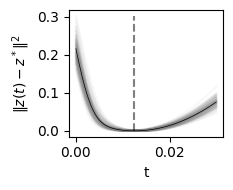

In [6]:
# Fig. 4c. The contrast: measured against the *static* z*, the state keeps moving. That is
# transport along the manifold, which is exactly what panel b shows the exponential map
# accounts for.
plt.figure(figsize=(2.5, 2))
for deviation in zstar_deviations:
    plt.plot(times, deviation, color="gray", alpha=0.05)
plt.plot(times, zstar_deviations.mean(axis=0), "k", linewidth=0.5)
plt.vlines(t_stars.mean(), ymin=0, ymax=zstar_deviations.max(), color="k", linestyle="--", alpha=0.5)
plt.xlabel("t")
plt.ylabel(r"$\|z(t) - z^*\|^2$")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "deviation_from_zstar.svg", dpi=300, bbox_inches="tight")
plt.savefig(FIGURE_DIR / "deviation_from_zstar.png", dpi=300, bbox_inches="tight")

In [7]:
# Three checks on what the figure claims.
z0 = np.random.default_rng(SEED).uniform(-1, 1, N) * 0.1
z = simulate(z0, U, M, DT, T, tau=TAU)
energy = lyapunov_energy(z)

# 1. Energy is non-increasing while genuinely off the manifold.
off_manifold = energy[:-1] > 1e-8
print(f"energy non-increasing off-manifold: {np.all(np.diff(energy)[off_manifold] <= 0)}")

# 2. On the manifold, sigma(z*) = 0, so the step is pure transport U z.
unit = z[-1] / np.linalg.norm(z[-1])
print(f"max |step(z*) - U z*| on manifold  = {np.abs(hypersphere_step(unit, U, M) - U @ unit).max():.2e}")

# 3. The Euler offset is O(dt), so halving dt should roughly halve it. This needs a
# longer run than the figure: at T = 0.03 the finest dt has not settled yet and is
# still approaching the manifold from inside.
offsets = [np.linalg.norm(simulate(z0, U, M, dt, T=0.06, tau=TAU)[-1]) - 1 for dt in (1e-4, 5e-5, 2.5e-5)]
print(f"||z|| - 1 at dt = 1e-4, 5e-5, 2.5e-5: {[f'{o:.2e}' for o in offsets]}")
print(f"  ratios: {[round(a / b, 2) for a, b in zip(offsets, offsets[1:])]}  (~2 => first order in dt)")

energy non-increasing off-manifold: True
max |step(z*) - U z*| on manifold  = 6.66e-15
||z|| - 1 at dt = 1e-4, 5e-5, 2.5e-5: ['4.54e-05', '2.27e-05', '1.13e-05']
  ratios: [np.float64(2.0), np.float64(2.0)]  (~2 => first order in dt)
